In [15]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
import glob as glob
import os

In [10]:
data_dir = "/Users/ani/work/projects/fast-transients/tidez/data/candidates"
glob_pattern = f"{test_data_dir}/*.fits"
data = glob.glob(glob_pattern)

print(f"Found {len(data)} files in {data_dir}")

Found 12 files in /Users/ani/work/projects/fast-transients/tidez/data/candidates


In [16]:
test_data = np.random.choice(data)
print(f"Using {os.path.basename(test_data)} for testing")

Using 34_A202502061452447m014625.fits for testing


In [23]:
with fits.open(test_data) as hdul:
    data = hdul[1].data
    header = hdul[1].header

In [21]:
data

FITS_rec([(0, 'c4d_250206_083511_xxx_g_v1', 'c4d_170301_085746_xxx_g_ls9', 60712.35777604, 'g', 'N3', 1945.02263879, 3864.61664201, 1945.02263879, 3864.61664201, 1922.58854528, 3847.65822502, 1945.07076652, 3864.0536568 ,       nan,       nan,         nan,    nan,    nan,        nan, [[ 1.07283020e+00,  5.99287415e+00, -4.80758667e-01, ..., -6.52766418e+00, -1.47305298e+00,  1.81259155e+00], [ 4.04631042e+00, -2.14268494e+00, -5.15325928e+00, ..., -6.06671143e+00, -3.71557617e+00, -1.41494751e-01], [-4.80593872e+00,  5.85191345e+00,  1.45777893e+01, ...,  9.12049866e+00, -3.66625977e+00, -1.30939331e+01], ..., [-2.46170044e+00, -6.46162415e+00,  5.03643799e+00, ..., -8.08561707e+00, -4.05303955e-01, -2.27676392e-01], [-4.31753540e+00,  1.17961121e+00, -2.73992920e+00, ...,  1.00622864e+01,  1.59325867e+01, -1.08917236e-01], [-5.17541504e+00,  7.74427795e+00, -2.79708862e-01, ..., -5.41632080e+00, -5.06571960e+00,  8.70748901e+00]], [[ 2.45246261e-01, -1.82039440e-01, -6.93510830e-01, .

In [24]:
header

XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =               351677 / length of dimension 1                          
NAXIS2  =                   82 / length of dimension 2                          
PCOUNT  =                    0 / number of group parameters                     
GCOUNT  =                    1 / number of groups                               
TFIELDS =                   37 / number of table fields                         
TTYPE1  = 'INDEX   '                                                            
TFORM1  = 'K       '                                                            
TTYPE2  = 'SCIENCE_NAME'                                                        
TFORM2  = '27A     '                                                            
TTYPE3  = 'TEMPLATE_NAME'   

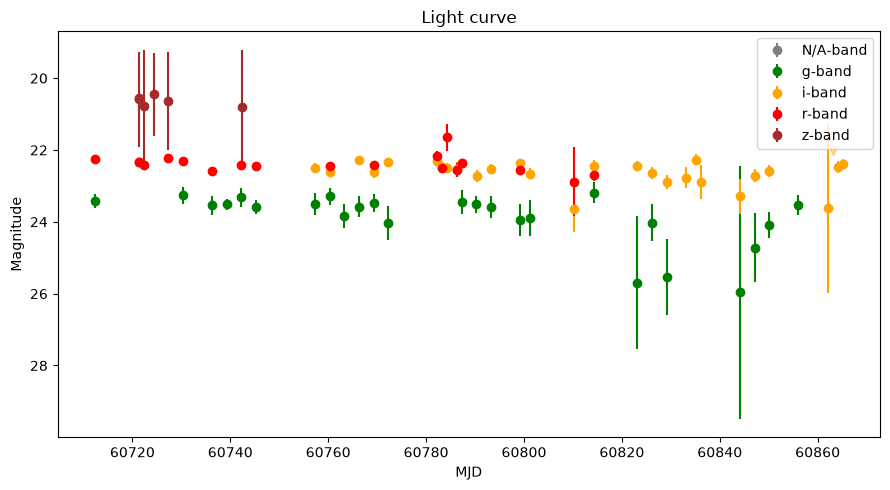

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

with fits.open(test_data) as hdul:
    data = hdul[1].data

mjd = data['MJD_OBS']
filt = data['FILTER']
mag = data['MAG_FPHOT']
magerr = data['MAGERR_FPHOT']
limmag5 = data['LIM_MAG5']
status = data['STATUS_FPHOT']

filters = np.unique(filt)
colors = {'g': 'green', 'r': 'red', 'i': 'orange', 'z': 'brown'}

fig, ax = plt.subplots(figsize=(9, 5))

for f in filters:
    mask = filt == f
    detected = mask & ~np.isnan(mag) & (magerr > 0)
    nondetected = mask & np.isnan(mag)

    ax.errorbar(mjd[detected], mag[detected], yerr=magerr[detected],
                fmt='o', color=colors.get(f, 'gray'), label=f'{f}-band')

    # plot non-detections as downward-pointing triangles at the 5-sigma limit
    ax.scatter(mjd[nondetected], limmag5[nondetected],
               marker='v', color=colors.get(f, 'gray'), alpha=0.4)

ax.invert_yaxis()  # brighter = up
ax.set_xlabel('MJD')
ax.set_ylabel('Magnitude')
ax.set_title('Light curve')
ax.legend()
plt.tight_layout()
# plt.savefig('lightcurve.png', dpi=150)
plt.show()